# Lekcja 4. Sfera Blocha

**Cel:** zobaczyć, że stan jednego kubitu to punkt na sferze, i nauczyć się czytać z tej sfery zarówno amplitudy, jak i wyniki pomiarów w różnych bazach.

## 1. Ile liczb naprawdę opisuje stan?

$(\alpha, \beta) \in \mathbb{C}^2 \cong \mathbb{R}^4$, czyli 4 liczby rzeczywiste. Dwie odpadają:

- **normalizacja** $|\alpha|^2 + |\beta|^2 = 1$ wycina sferę $S^3 \subset \mathbb{R}^4$;
- **faza globalna** to utożsamienie punktów różniących się czynnikiem $e^{i\gamma}$, czyli iloraz $S^3 / U(1)$.

Zostają dwie liczby, a $S^3/U(1) \cong S^2 = \mathbb{CP}^1$ (włóknienie Hopfa). To jest właśnie sfera Blocha.

## 2. Parametryzacja

Skoro $|\alpha|^2 + |\beta|^2 = 1$, piszemy $|\alpha| = \cos(\theta/2)$, $|\beta| = \sin(\theta/2)$ dla $\theta \in [0, \pi]$, a fazę globalną wybieramy tak, żeby $\alpha$ było rzeczywiste:

$$\boxed{\;\alpha = \cos\tfrac{\theta}{2}, \qquad \beta = e^{i\varphi}\sin\tfrac{\theta}{2}\;}$$

- $\theta$ (odległość od bieguna północnego) ustala **moduły**: ile stanu jest przy $e_0$, a ile przy $e_1$. Na przykład $P(0) = \cos^2(\theta/2)$.
- $\varphi$ (długość geograficzna, wokół osi $z$) to **faza względna**: o ile $\beta$ jest obrócone względem $\alpha$ na płaszczyźnie zespolonej.

> **To było trudne:** to wydaje się mało intuicyjne, że faza względna jest „długością geograficzną”. Pomaga obchód po równiku: na całym równiku jest 50/50 zera i jedynki ($\theta = \pi/2$ stoi w miejscu), a zmienia się tylko przesunięcie fazy między nimi. Dlatego ruch odbywa się dookoła osi $z$.

## 3. Mapa sfery i osie jako bazy

| Punkt | $\theta$ | $\varphi$ | Etykieta | Wektor |
|---|---|---|---|---|
| biegun N | 0 | – | $\lvert 0\rangle$ | $(1, 0)$ |
| biegun S | $\pi$ | – | $\lvert 1\rangle$ | $(0, 1)$ |
| równik, oś $+x$ | $\pi/2$ | 0 | $\lvert +\rangle$ | $(1, 1)/\sqrt2$ |
| równik, oś $-x$ | $\pi/2$ | $\pi$ | $\lvert -\rangle$ | $(1, -1)/\sqrt2$ |
| równik, oś $+y$ | $\pi/2$ | $\pi/2$ | $\lvert {+i}\rangle$ | $(1, i)/\sqrt2$ |
| równik, oś $-y$ | $\pi/2$ | $-\pi/2$ | $\lvert {-i}\rangle$ | $(1, -i)/\sqrt2$ |

**Dlaczego $\theta/2$?** Wektory ortogonalne w $\mathbb{C}^2$ (kąt 90°) muszą na sferze leżeć naprzeciw siebie (kąt 180°). Każda para przeciwległych punktów to **jedna baza pomiarowa**: oś $z \to \{e_0, e_1\}$, oś $x \to \{u_+, u_-\}$, oś $y \to \{|{+i}\rangle, |{-i}\rangle\}$.

## 4. Współrzędne punktu i pomiar jako rzut

Punkt na sferze we współrzędnych kartezjańskich:

$$(x, y, z) = (\sin\theta\cos\varphi,\; \sin\theta\sin\varphi,\; \cos\theta).$$

Te same współrzędne przez amplitudy:

$$z = |\alpha|^2 - |\beta|^2, \qquad x + iy = 2\,\bar\alpha\beta.$$

Rzut punktu na płaszczyznę równika to dokładnie liczba zespolona $2\bar\alpha\beta = \sin\theta\, e^{i\varphi}$. Sfera nie pokazuje osobno $\alpha$ ani $\beta$ (zawierają nieistotną fazę globalną), tylko ich relację $\bar\alpha\beta$. To jest dokładnie ta sama wielkość, która w lekcji 3 dawała wyraz interferencyjny.

**Pomiar w danej bazie to rzut na odpowiednią oś:**

$$P(0) = \frac{1 + z}{2}, \qquad P(+) = \frac{1 + x}{2}, \qquad P(+i) = \frac{1 + y}{2}.$$

Wzór $P(+) = \tfrac12(1 + 2|\alpha||\beta|\cos\varphi)$ z lekcji 3 to to samo, bo $2|\alpha||\beta| = 2\cos\tfrac\theta2\sin\tfrac\theta2 = \sin\theta$.

**Zagadka z lekcji 3:** stany $|{+i}\rangle$ i $|{-i}\rangle$ leżą na osi $y$, więc oba mają $x = 0$ i $z = 0$. W bazach $z$ i $x$ dają 50/50; rozróżnia je dopiero pomiar wzdłuż osi $y$. Dlatego do odtworzenia nieznanego stanu potrzeba pomiarów w **trzech** bazach (tomografia stanu).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
GREEN, DARK, LIGHT, GREY, ORANGE = "#44B749", "#1A8A1F", "#96E199", "#8A8A8A", "#E08A00"

e0 = np.array([1, 0], dtype=complex)   # etykieta |0⟩
e1 = np.array([0, 1], dtype=complex)   # etykieta |1⟩

def norm(v):
    return np.sqrt(np.sum(np.abs(v) ** 2))

def show(v, n=None):
    """Wypisz wektor stanu z etykietami bitów (etykieta = pozycja w zapisie dwójkowym)."""
    v = np.asarray(v)
    n = n or int(np.log2(len(v)))
    for k, a in enumerate(v):
        if abs(a) > 1e-12:
            print(f"  pozycja {k} ({format(k, f'0{n}b')}): amplituda {np.round(a, 3)}, P = {abs(a)**2:.3f}")

def amplitudy(theta, phi):
    return np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])

def bloch(v):
    """Współrzędne (x, y, z) stanu v na sferze Blocha."""
    a, b = v
    c = 2 * np.conj(a) * b
    return np.array([c.real, c.imag, abs(a) ** 2 - abs(b) ** 2])

up, um = (e0 + e1) / np.sqrt(2), (e0 - e1) / np.sqrt(2)
theta, phi = np.pi / 3, np.pi / 4
v = amplitudy(theta, phi)
x, y, z = bloch(v)
print("amplitudy:", np.round(v, 3))
print("(x, y, z) =", np.round([x, y, z], 3))
print(f"P(0) z reguły Borna: {abs(v[0])**2:.3f}   z rzutu (1+z)/2: {(1+z)/2:.3f}")
print(f"P(+) z reguły Borna: {abs(np.vdot(up, v))**2:.3f}   z rzutu (1+x)/2: {(1+x)/2:.3f}")

amplitudy: [0.866+0.j    0.354+0.354j]
(x, y, z) = [0.612 0.612 0.5  ]
P(0) z reguły Borna: 0.750   z rzutu (1+z)/2: 0.750
P(+) z reguły Borna: 0.806   z rzutu (1+x)/2: 0.806

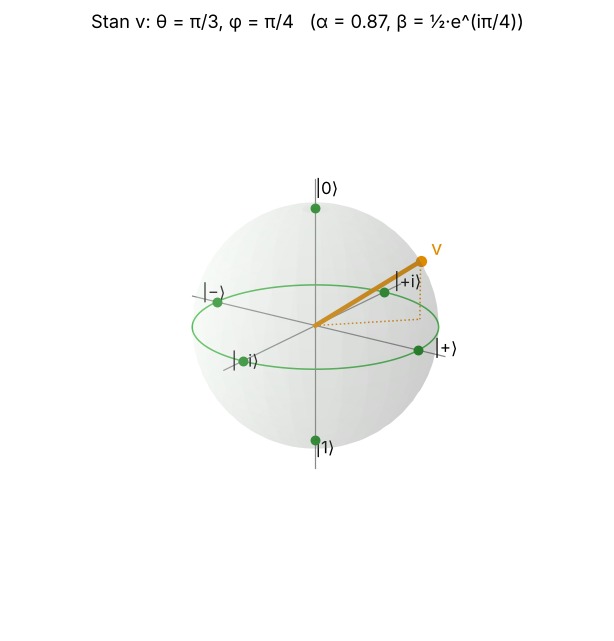

In [2]:
fig = plt.figure(figsize=(7, 7)); ax = fig.add_subplot(111, projection="3d")
ax.view_init(elev=20, azim=-55); ax.set_box_aspect((1, 1, 1))
u_, w_ = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
ax.plot_surface(np.cos(u_)*np.sin(w_), np.sin(u_)*np.sin(w_), np.cos(w_), color="#EAF7EA", alpha=0.15, lw=0)
t = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(t), np.sin(t), 0, color=GREEN, lw=1)
for d in np.eye(3):
    ax.plot(*np.c_[-1.25*d, 1.25*d], color=GREY, lw=0.8)
for p, l in [((0,0,1),"|0⟩"), ((0,0,-1),"|1⟩"), ((1,0,0),"|+⟩"), ((-1,0,0),"|−⟩"), ((0,1,0),"|+i⟩"), ((0,-1,0),"|−i⟩")]:
    ax.scatter(*p, color=DARK, s=30); ax.text(p[0]*1.15, p[1]*1.15, p[2]*1.12, l, fontsize=11)
ax.plot([0, x], [0, y], [0, z], color=ORANGE, lw=3); ax.scatter(x, y, z, color=ORANGE, s=40)
ax.text(x*1.1, y*1.1, z*1.1, "v", color=ORANGE, fontsize=13)
ax.plot([x, x], [y, y], [z, 0], color=ORANGE, ls=":", lw=1); ax.plot([0, x], [0, y], [0, 0], color=ORANGE, ls=":", lw=1)
ax.set_axis_off(); ax.set_title(f"Stan v: θ = π/3, φ = π/4   (α = {v[0].real:.2f}, β = ½·e^(iπ/4))")

## 5. Ograniczenie

Sfera Blocha działa tylko dla **jednego** kubitu. Stan dwóch kubitów żyje w $\mathbb{C}^4$, a stanu splątanego nie da się przedstawić jako dwóch punktów na dwóch sferach (lekcja 7). Pojedynczy kubit wyjęty ze stanu Bella odpowiada środkowi kuli, a nie punktowi na sferze. Punkty we wnętrzu kuli to stany mieszane (macierze gęstości), które wykraczają poza ten kurs.

## Podsumowanie

> Stan kubitu to punkt na sferze $S^2$: $\alpha = \cos\frac\theta2$, $\beta = e^{i\varphi}\sin\frac\theta2$. Wysokość ($\theta$) mówi, ile jest zera, a ile jedynki; długość ($\varphi$) to faza względna. Przeciwległe punkty to stany ortogonalne, a każda oś to jedna baza pomiarowa. Pomiar w danej bazie to rzut punktu na tę oś: $P = (1 + \text{współrzędna})/2$.

## Zadania

1. Gdzie na sferze leży stan $(\sqrt3/2, 1/2)$? Podaj $\theta$ i $\varphi$.
2. Stan ma $\theta = \pi/3$, $\varphi = \pi$. Zapisz go jako $(\alpha, \beta)$ i policz $P(0)$ oraz $P(+)$.
3. Dlaczego żaden punkt sfery nie daje jednocześnie $P(0) = 1$ i $P(+) = 1$?